In [10]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import joblib

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score,
    precision_score, recall_score, confusion_matrix
)
from IPython.display import display

RANDOM_STATE = 42
TEST_SIZE = 0.30

# Change this to your downloaded dataset path if it is not beside this notebook.
# Examples: "sentiment.csv" or r"C:\Users\YourName\Downloads\sentiment.csv"
DATA_PATH = Path(r"C:\Users\PMY\Desktop\New folder (2)\text.csv")

TEXT_COLUMN = "text"
LABEL_COLUMN = "label"

LABEL_NAMES = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise",
}
OUTPUT_DIR = Path("sentiment_model_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset path:", DATA_PATH.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

Dataset path: C:\Users\PMY\Desktop\New folder (2)\text.csv
Output folder: C:\Users\PMY\Desktop\New folder (2)\sentiment_model_output


In [11]:
for resource in ["stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception as exc:
        print(f"Could not download NLTK resource {resource}: {exc}")

try:
    STOP_WORDS = set(stopwords.words("english"))
except LookupError as exc:
    raise LookupError(
        "NLTK English stopwords are unavailable. Run nltk.download('stopwords') "
        "in a notebook cell with internet access."
    ) from exc

lemmatizer = WordNetLemmatizer()
print(f"Loaded {len(STOP_WORDS)} English stop words.")

Loaded 198 English stop words.


In [12]:
def load_dataset(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path.resolve()}\n"
            "Set DATA_PATH in the configuration cell to the correct file path."
        )

    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError("Unsupported file type. Use CSV, Excel, or Parquet.")

df = load_dataset(DATA_PATH)

missing_columns = {TEXT_COLUMN, LABEL_COLUMN} - set(df.columns)
if missing_columns:
    raise ValueError(
        f"Missing required column(s): {sorted(missing_columns)}. "
        f"Available columns: {list(df.columns)}"
    )

df = df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna("").astype(str).str.strip()
df = df[df[TEXT_COLUMN].ne("")]
df[LABEL_COLUMN] = pd.to_numeric(df[LABEL_COLUMN], errors="coerce")
df = df.dropna(subset=[LABEL_COLUMN])
df[LABEL_COLUMN] = df[LABEL_COLUMN].astype(int)
df = df.drop_duplicates(subset=[TEXT_COLUMN, LABEL_COLUMN]).reset_index(drop=True)

unexpected = sorted(set(df[LABEL_COLUMN].unique()) - set(LABEL_NAMES))
if unexpected:
    raise ValueError(
        f"Unexpected label value(s): {unexpected}. Expected numeric labels 0 through 5."
    )

missing_labels = sorted(set(LABEL_NAMES) - set(df[LABEL_COLUMN].unique()))
if missing_labels:
    raise ValueError(
        f"These expected classes are absent from the dataset: {missing_labels}. "
        "Cannot train/evaluate all six classes without examples for each."
    )

print("Rows after basic cleaning:", len(df))
print("\nOriginal class counts:")
display(
    df[LABEL_COLUMN].value_counts()
      .sort_index()
      .rename(index=LABEL_NAMES)
      .rename("count")
      .to_frame()
)
display(df.head())

Rows after basic cleaning: 416123

Original class counts:


,count
label,
sadness,120989
joy,140779
love,34497
anger,57235
fear,47664
surprise,14959


,text,label
0,i just feel really helpless and heavy hearted,4
1,ive enjoyed being able to slouch about relax a...,0
2,i gave up my internship with the dmrg and am f...,4
3,i dont know i feel so lost,0
4,i am a kindergarten teacher and i am thoroughl...,4


In [13]:
class_counts = df[LABEL_COLUMN].value_counts()
min_class_count = int(class_counts.min())

balanced_df = (
    df.groupby(LABEL_COLUMN, group_keys=False)
      .sample(n=min_class_count, random_state=RANDOM_STATE)
      .sample(frac=1, random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

print("Examples per class after balancing:", min_class_count)
print("Total balanced examples:", len(balanced_df))
display(
    balanced_df[LABEL_COLUMN].value_counts()
      .sort_index()
      .rename(index=LABEL_NAMES)
      .rename("count")
      .to_frame()
)

balanced_df.to_csv(OUTPUT_DIR / "balanced_dataset.csv", index=False)
print("Saved balanced dataset to:", OUTPUT_DIR / "balanced_dataset.csv")

Examples per class after balancing: 14959
Total balanced examples: 89754


,count
label,
sadness,14959
joy,14959
love,14959
anger,14959
fear,14959
surprise,14959


Saved balanced dataset to: sentiment_model_output\balanced_dataset.csv


In [14]:
# Keep negation words even though they occur in the standard English stop-word list.
NEGATION_WORDS = {"no", "not", "nor"}
CUSTOM_STOP_WORDS = STOP_WORDS - NEGATION_WORDS

def preprocess_text(text: str) -> str:
    text = str(text).lower()
    # Keep alphabetic tokens; punctuation, digits and URLs are removed.
    tokens = re.findall(r"[a-z]+", text)
    processed = []
    for token in tokens:
        if token in CUSTOM_STOP_WORDS:
            continue
        lemma = lemmatizer.lemmatize(token)
        if lemma:
            processed.append(lemma)
    return " ".join(processed)

balanced_df["processed_text"] = balanced_df[TEXT_COLUMN].apply(preprocess_text)

# A few rows can become empty after cleaning; drop them before splitting.
balanced_df = balanced_df[balanced_df["processed_text"].str.strip().ne("")].reset_index(drop=True)

print("Before / after preprocessing:")
display(balanced_df[[TEXT_COLUMN, "processed_text", LABEL_COLUMN]].head(10))
print("\nClass counts after preprocessing:")
display(
    balanced_df[LABEL_COLUMN].value_counts()
      .sort_index()
      .rename(index=LABEL_NAMES)
      .rename("count")
      .to_frame()
)

balanced_df.to_csv(OUTPUT_DIR / "balanced_preprocessed_dataset.csv", index=False)

Before / after preprocessing:


,text,processed_text,label
0,i feel like you rarely get to see something th...,feel like rarely get see something like petrif...,4
1,i am very resolved in how i feel about this pl...,resolved feel please dont give argument showin...,3
2,i cannot imagine the emptiness she must feel b...,cannot imagine emptiness must feel know feel a...,0
3,i have already built up a huge rapport with so...,already built huge rapport many different clie...,2
4,i would say that what i feel creative capital ...,would say feel creative capital taught kind pi...,1
5,i am a football fan since god knows when twent...,football fan since god know twenty maybe thirt...,2
6,i do feel passionate about at least in how it ...,feel passionate least play role hoopers career,2
7,i sent her this long paragraph message about h...,sent long paragraph message worth two second t...,0
8,i feel petty about that now,feel petty,3
9,i didn t feel too intimidated and large enough...,feel intimidated large enough felt worth trip,4



Class counts after preprocessing:


,count
label,
sadness,14958
joy,14959
love,14959
anger,14958
fear,14959
surprise,14959


In [15]:
X = balanced_df["processed_text"]
y = balanced_df[LABEL_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)} ({len(X_train)/len(X):.1%})")
print(f"Testing samples:  {len(X_test)} ({len(X_test)/len(X):.1%})")
print("\nTraining class counts:")
display(y_train.value_counts().sort_index().rename(index=LABEL_NAMES).rename("count").to_frame())
print("\nTesting class counts:")
display(y_test.value_counts().sort_index().rename(index=LABEL_NAMES).rename("count").to_frame())

Training samples: 62826 (70.0%)
Testing samples:  26926 (30.0%)

Training class counts:


,count
label,
sadness,10471
joy,10471
love,10471
anger,10471
fear,10471
surprise,10471



Testing class counts:


,count
label,
sadness,4487
joy,4488
love,4488
anger,4487
fear,4488
surprise,4488


In [16]:
tfidf = TfidfVectorizer(
    max_features=100_000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

svm_model = LinearSVC(C=1.0, class_weight=None, random_state=RANDOM_STATE)
svm_model.fit(X_train_tfidf, y_train)

y_pred = svm_model.predict(X_test_tfidf)
print("Model training complete.")

Training TF-IDF shape: (62826, 66253)
Testing TF-IDF shape: (26926, 66253)


c:\Users\PMY\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


Model training complete.


In [22]:
import joblib
from pathlib import Path

output_dir = Path("sentiment_model_output")
output_dir.mkdir(exist_ok=True)

joblib.dump(svm_model, output_dir / "linear_svm_model.joblib")
joblib.dump(tfidf, output_dir / "tfidf_vectorizer.joblib")
joblib.dump(LABEL_NAMES, output_dir / "label_mapping.joblib")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [17]:
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
macro_precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
macro_recall = recall_score(y_test, y_pred, average="macro", zero_division=0)

summary = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score", "Weighted F1-score"],
    "Score": [accuracy, macro_precision, macro_recall, macro_f1, weighted_f1]
})
display(summary.style.format({"Score": "{:.4f}"}))

print("\nPer-class classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(LABEL_NAMES.keys()),
    target_names=[LABEL_NAMES[i] for i in LABEL_NAMES],
    digits=4,
    zero_division=0
))

report_dict = classification_report(
    y_test,
    y_pred,
    labels=list(LABEL_NAMES.keys()),
    target_names=[LABEL_NAMES[i] for i in LABEL_NAMES],
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report_dict).transpose().to_csv(OUTPUT_DIR / "classification_report.csv")
summary.to_csv(OUTPUT_DIR / "summary_metrics.csv", index=False)
print("Saved evaluation reports in:", OUTPUT_DIR.resolve())

,Metric,Score
0,Accuracy,0.9161
1,Macro Precision,0.9165
2,Macro Recall,0.9161
3,Macro F1-score,0.9160
4,Weighted F1-score,0.9160



Per-class classification report:
              precision    recall  f1-score   support

     sadness     0.9459    0.9231    0.9344      4487
         joy     0.9358    0.8837    0.9090      4488
        love     0.9083    0.9583    0.9327      4488
       anger     0.9286    0.9276    0.9281      4487
        fear     0.8837    0.8650    0.8742      4488
    surprise     0.8968    0.9389    0.9174      4488

    accuracy                         0.9161     26926
   macro avg     0.9165    0.9161    0.9160     26926
weighted avg     0.9165    0.9161    0.9160     26926

Saved evaluation reports in: C:\Users\PMY\Desktop\New folder (2)\sentiment_model_output


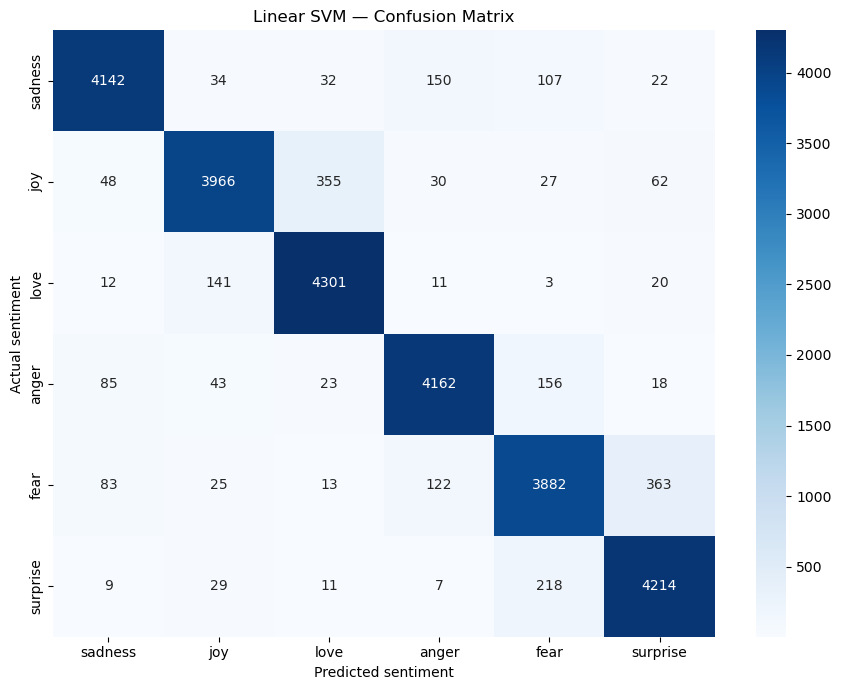

In [18]:
cm = confusion_matrix(y_test, y_pred, labels=list(LABEL_NAMES.keys()))
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[LABEL_NAMES[i] for i in LABEL_NAMES],
    yticklabels=[LABEL_NAMES[i] for i in LABEL_NAMES]
)
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.title("Linear SVM — Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

,Sentiment,F1-score
0,sadness,0.9344
2,love,0.9327
3,anger,0.9281
5,surprise,0.9174
1,joy,0.9090
4,fear,0.8742


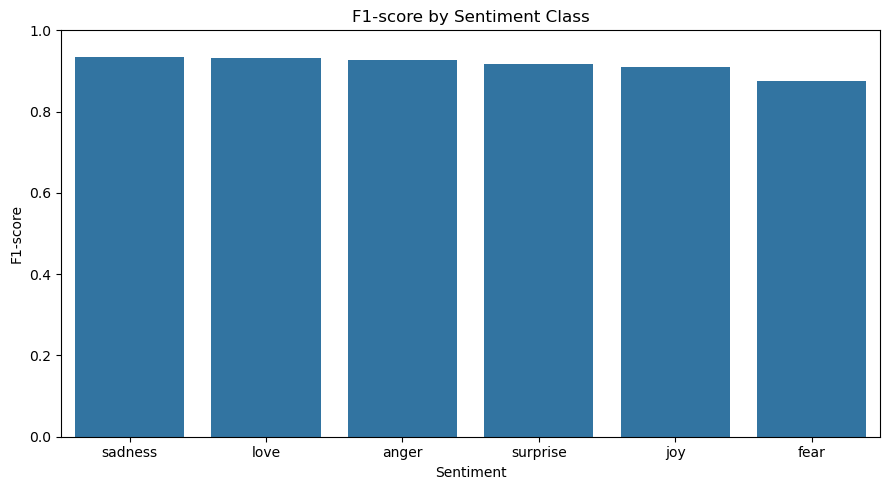

In [19]:
per_class_f1 = f1_score(
    y_test, y_pred,
    labels=list(LABEL_NAMES.keys()),
    average=None,
    zero_division=0
)

f1_df = pd.DataFrame({
    "Sentiment": [LABEL_NAMES[i] for i in LABEL_NAMES],
    "F1-score": per_class_f1
}).sort_values("F1-score", ascending=False)

display(f1_df.style.format({"F1-score": "{:.4f}"}))

plt.figure(figsize=(9, 5))
sns.barplot(data=f1_df, x="Sentiment", y="F1-score")
plt.ylim(0, 1)
plt.title("F1-score by Sentiment Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()
f1_df.to_csv(OUTPUT_DIR / "per_class_f1.csv", index=False)

In [20]:
def predict_sentiment(user_text: str) -> str:
    cleaned = preprocess_text(user_text)
    if not cleaned:
        return "Unable to predict: please enter a sentence with meaningful English words."
    features = tfidf.transform([cleaned])
    predicted_label = int(svm_model.predict(features)[0])
    return LABEL_NAMES[predicted_label]

while True:
    try:
        user_text = input("Enter a sentence (or type 'quit' to stop): ").strip()
    except (EOFError, KeyboardInterrupt):
        print("\nPrediction session ended.")
        break

    if user_text.lower() in {"quit", "exit", "q"}:
        print("Prediction session ended.")
        break
    if not user_text:
        print("Please enter a non-empty sentence.")
        continue

    print("Predicted sentiment:", predict_sentiment(user_text))
    print("-" * 50)

Predicted sentiment: sadness
--------------------------------------------------
Prediction session ended.
